# 10. Molecular dynamics

- Teaches how to run a short molecular dynamics run, MD, from the terminal: the atoms are moved through time in small steps under the forces of the model, with a thermostat that keeps the temperature near a target
- A calculation whose answer depends on settings that the command fills in silently if you leave them out, and where finishing without an error says nothing about whether the run is usable, canon `C5`
- One system: a Pt(1 1 1) slab with six water molecules above it, 45 atoms, with the model `mace` in every command
- Before you start: modules 00 to 09 finished, the `mlip-mace` environment active, and Jupyter Lab running
    - The kernel shown at the top right of this notebook is "Python 3 (ipykernel)", the Python of that environment
    - The model weights sit in `~/.cache/mace/` from step 10 of module 00, so nothing is downloaded here
- After this you can build a slab with water above it, run an MD from the terminal with every setting named, read the two files it writes, tell a run whose temperature stays bounded from a run that blows up, continue a run with `--resume`, and say which settings of an MD are decisions of the project and not defaults

### Before you run this for a project

- The values in this notebook are teaching values, chosen so it runs on a laptop in minutes
- In a project, the items below are decided by your supervisor and written in the project's `CANON.md`; they are never taken from a tool default
    - `C1` MLIP model and head: this notebook uses `mace` (MACE-MP-0); the project may use another; leaving `--mlip` out makes `mlip md run` choose a model for you and print which one, so every command here names it
    - `C5` MD run decisions: the ensemble, the temperature, the timestep, and the total number of steps with the part that is equilibration and the part that is production, decided per project; the options of `mlip md run` have defaults that run silently if you leave them out, and the last section lays them next to the project's own values
- If a value is not recorded, ask before running; the tool will not stop you

## 0. The setup cell

- Run this cell first, every time you open the notebook
- This notebook runs `mliprun` commands from the terminal side, as modules 07 and 09 did, and reads the files they write
    - `work/` fills up as you go: `work/md/` for the main run, `work/md_dt2/` and the three folders `work/md_dt2_b/`, `work/md_dt2_c/` and `work/md_dt2_d/` for the timestep test, and `work/md_resume_check/` for a copy of the main run
- `sys.path.insert(0, str(Path("../../scripts").resolve()))` puts the repository's `scripts` folder at the front of the list of folders Python searches, as in modules 07 to 09, so `from onboarding_structures import ...` works
- `sys`, `pathlib`, `json`, `re`, `shutil`, `subprocess`, `textwrap`, `time` and `importlib.metadata` all come with Python
    - `version` comes from `importlib.metadata`, and `version("mliprun")` gives the version of an installed package as text
- `numpy` is imported under the short name `np`, `pandas` under `pd` and `matplotlib.pyplot` under `plt`, as in earlier modules
- `molecule` comes from `ase.build`, and it builds a small molecule such as water from ASE's own table; `write` and `read` come from `ase.io`, as in earlier modules, and `plot_atoms` comes from `ase.visualize.plot`, as in modules 04 and 09
- `MLIP = Path(sys.executable).parent / "mlip"` is the `mlip` command of this environment, the same line modules 07 to 09 used
    - In the terminal you type `mlip` on its own, with the `mlip-mace` environment active, and that is what the command lines printed below show
- `run_mlip(arguments, show=True)` prints the command as you would type it, runs it, prints how long it took, and stops the notebook if the command itself failed
    - With `show=False` it prints nothing unless the command failed, which the section on the timestep test uses for its repeats
- `shorten(text)`, `last_lines(text, n)` and `first_lines(text, n)` replace this computer's own folder names in a block of terminal output and keep its last or first `n` lines that carry anything
    - Nothing else is changed; run the same command in a terminal and you see the same lines with the full paths in them
- `last_stage(folder)` reads `mliprun_run.json` in a folder and returns its last stage, the record of the most recent run in that folder

In [1]:
import json
import re
import shutil
import subprocess
import sys
import textwrap
import time
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ase.build import molecule
from ase.io import read, write
from ase.visualize.plot import plot_atoms

sys.path.insert(0, str(Path("../../scripts").resolve()))
from onboarding_structures import pt111_slab

WORK = Path("work")
WORK.mkdir(exist_ok=True)

MLIP = Path(sys.executable).parent / "mlip"
HERE = Path.cwd()
ENVIRONMENT = Path(sys.executable).parent.parent
HOME = Path.home()


def shorten(text):
    # Replace this computer's own folder names in a block of terminal output.
    return (text.replace(str(HERE) + "/", "")
                .replace(str(ENVIRONMENT), "<environment>")
                .replace(str(HOME), "~"))


def last_lines(text, n):
    # The last n lines of a block of output that carry anything.
    kept = [line for line in shorten(text).splitlines() if line.strip()]
    return "\n".join(kept[-n:])


def first_lines(text, n):
    # The first n lines of a block of output that carry anything.
    kept = [line for line in shorten(text).splitlines() if line.strip()]
    return "\n".join(kept[:n])


def run_mlip(arguments, show=True):
    # Run one mlip command from this folder and return the result.
    if show:
        print("Command, as you would type it in the terminal")
        print(" ".join(["mlip"] + arguments))
    started = time.perf_counter()
    result = subprocess.run([str(MLIP)] + arguments, capture_output=True, text=True)
    if show:
        print()
        print("Seconds the command took")
        print(round(time.perf_counter() - started, 1))
    if result.returncode != 0:
        print()
        print("The command failed, and this is the end of what it wrote to its error stream")
        print(last_lines(result.stderr, 15))
        raise SystemExit("mlip command failed")
    return result


def last_stage(folder):
    # The last stage of the run record mliprun wrote in that folder.
    record = json.loads((Path(folder) / "mliprun_run.json").read_text())
    return record["stages"][-1]


print("Folder this notebook writes into")
print(WORK)
print("The mlip command of this environment was found")
print(MLIP.exists())
print("Version of mliprun")
print(version("mliprun"))

Folder this notebook writes into
work
The mlip command of this environment was found
True
Version of mliprun
0.4.0


## 1. What MD is

- Molecular dynamics follows the atoms through time by solving Newton's equations of motion in small steps
    - The model gives the energy of an arrangement of atoms, and minus its slope with respect to each position is the force on that atom
    - Newton's second law, mass times acceleration equals force, gives how the velocities change, and the velocities give how the positions change
    - One step moves positions and velocities forward by a short time, the timestep, and then needs the forces at the new positions
    - A run is many such steps in a row, so its run time grows with the number of steps
- The timestep is the time moved forward in each step, and `--timestep` takes it in fs, where 1 fs is 10⁻¹⁵ s
    - The integrator, the rule that turns forces into new positions, treats the force as nearly constant during one step, so a step has to be short compared with the fastest vibration in the system
    - General background, not measured on this page: in a system that contains water the fastest vibration is the O–H stretch, because H is the lightest atom, so hydrogen sets the largest timestep that works
    - The section on the timestep test runs 2.0 fs next to the 0.5 fs of the main run and prints what happens to the same system
- An ensemble says which quantities the run holds fixed
    - NVE holds the number of atoms, the volume and the total energy, and has no thermostat
    - NVT holds the number of atoms and the volume, and a thermostat keeps the temperature near a target; this is what this notebook runs
    - NPT also lets the cell change so that a pressure is held, and it is not used in this module
- A thermostat does not set the temperature of a step; it makes the temperature fluctuate around the target
    - The temperature of a group of atoms is a measure of their kinetic energy: `T = 2 E_kin / (N_dof k_B)`, with `N_dof` the number of degrees of freedom and `k_B` the Boltzmann constant
    - The thermostat adds and removes kinetic energy so that over a long run the temperature is distributed around the target, which means that any one step is above or below it
    - The Langevin thermostat does this with two forces on the atoms: a friction force that slows an atom, and a random force that pushes it
    - `--friction 0.01` is in fs⁻¹, and its inverse, 100 fs, is the time in which friction alone would reduce a velocity by a factor of e
- The starting velocities and the random force both come from random numbers
    - `--temperature 300` is the target in K, and in an NVT run that is not resumed it is also the temperature of the random draw that gives the atoms their first velocities
    - The command passes no seed to either random draw, so two runs of the same command give different numbers, and the numbers saved in this notebook belong to one run
- Equilibration and production are the two parts of a run
    - A run started from a hand-built structure, such as water molecules placed above a slab, generally has a first part that is not typical of the target temperature
    - The first part of the run follows that start and is discarded, which is the equilibration; the rest is the production, and averages are taken from it only
    - How long the equilibration lasts is not given by a formula; it is judged from the run, by looking for a trend in block averages of the temperature and the potential energy, and the section on reading the run prints block means for this run
    - The temperature touching the target once is not enough, because it fluctuates; a trend in the block means is the sign that the run has not settled

## 2. A slab with a few water molecules

- The structure is the Pt(1 1 1) slab of the earlier modules, three layers of 3 by 3 atoms with the bottom layer fixed, `pt111_slab(size=(3, 3, 3), vacuum=12)`, and six water molecules above it
    - The vacuum is 12 Å instead of the 10 Å of earlier modules, so that molecules placed up to 6 Å above the top layer still sit well inside the cell
- The six molecules are placed on a grid of 3 by 2 points across the surface, one molecule per point, each with its O atom about 3 to 6 Å above the top layer and a random orientation
    - `molecule("H2O")` builds one water molecule, and `euler_rotate(phi, theta, psi, center=(0, 0, 0))` turns it by three angles in degrees about the origin of its own coordinates, which is 0.12 Å from its O atom
    - The height of 3 to 6 Å is drawn for that origin and not for the O atom, so the O atom is within 0.12 Å of it
    - `np.random.default_rng(SEED)` makes a random-number generator whose numbers are fixed by the seed, here 11, so that every run of this cell builds the same structure; `rng.uniform(low, high)` draws one number in that range
    - `phi` and `psi` are drawn from 0 to 360 degrees, and `theta` is the arc cosine of a number drawn from -1 to 1, which is the choice that makes all orientations equally likely; `np.arccos` gives the angle in radians and `np.degrees` turns it into degrees
    - `get_distances(i, indices, mic=True)` gives the distance from atom `i` to each of the atoms in a list, taking the shortest way across the periodic boundary, as in module 05
- A structure placed by random orientations can put two molecules on top of each other, so the cell measures the shortest distance between atoms of two different molecules, and the shortest distance from any water atom to a Pt atom, and stops if the first is under 1.5 Å
    - 1.5 Å is a limit chosen for this teaching structure and not a standard value
    - `np.arange(a, b)` is the whole numbers from `a` up to but not including `b`, and `.reshape(6, 3)` lays them out as six rows of three, one row per molecule
    - `.max()` and `.min()` of an array give its largest and its smallest value, `.tolist()` turns an array into a list, and `.ravel()` flattens a table of rows into one row
- The file is written with `write(..., format="vasp", direct=True, sort=True)`, as in module 07, so atoms of one element are listed together: 12 H, then 6 O, then 27 Pt
    - The output of an MD run goes next to the structure file, so the file is written into `work/md/` and the files of the run appear there
- `get_number_of_degrees_of_freedom()` gives `N_dof` of the temperature formula in the section above: three per atom, minus the three of every atom the `FixAtoms` constraint holds
    - `constraints[0].get_indices()` is the list of the fixed atoms, as in module 05, and the cell prints its length; the 45 atoms have 135 coordinates and the 9 fixed atoms take away 27 of them
- In the figure:
    - A side view of the starting structure: three rows of Pt atoms at the bottom, with the six molecules above them at different heights and in different orientations
    - Red is O and white is H

Random seed of the placement
11
Atoms in the structure
45
Atoms held fixed
9
Degrees of freedom of the temperature
108

Height of the O atom of each molecule above the top Pt layer, in the order placed (Å)
[3.09, 3.49, 4.56, 5.31, 4.65, 4.38]
Shortest distance between atoms of two different water molecules (Å)
2.03
Shortest distance from a water atom to a Pt atom (Å)
2.71
File written
work/md/POSCAR


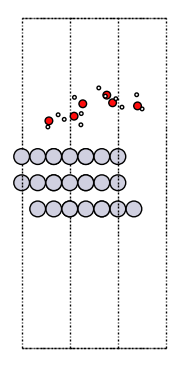

In [2]:
SEED = 11
MD_DIR = WORK / "md"
MD_DIR.mkdir(exist_ok=True)

slab = pt111_slab(size=(3, 3, 3), vacuum=12)
n_slab = len(slab)
top_z = slab.positions[:, 2].max()
a_vec, b_vec = slab.cell[0], slab.cell[1]
rng = np.random.default_rng(SEED)

system = slab.copy()
for i in range(3):
    for j in range(2):
        water = molecule("H2O")
        water.euler_rotate(phi=rng.uniform(0, 360),
                           theta=np.degrees(np.arccos(rng.uniform(-1, 1))),
                           psi=rng.uniform(0, 360), center=(0, 0, 0))
        height = rng.uniform(3, 6)
        xy = (i + 0.5) / 3 * a_vec + (j + 0.5) / 2 * b_vec
        water.translate([xy[0], xy[1], top_z + height])
        system += water

water_idx = np.arange(n_slab, len(system)).reshape(6, 3)
between = []
for p in range(6):
    for q in range(p + 1, 6):
        for i in water_idx[p]:
            between.append(system.get_distances(int(i), water_idx[q].tolist(), mic=True).min())
min_between = min(between)
min_to_slab = min(system.get_distances(int(i), list(range(n_slab)), mic=True).min()
                  for i in water_idx.ravel())

write(MD_DIR / "POSCAR", system, format="vasp", direct=True, sort=True)

print("Random seed of the placement")
print(SEED)
print("Atoms in the structure")
print(len(system))
print("Atoms held fixed")
print(len(system.constraints[0].get_indices()))
print("Degrees of freedom of the temperature")
print(system.get_number_of_degrees_of_freedom())
print()
print("Height of the O atom of each molecule above the top Pt layer, in the order placed (Å)")
print([round(float(z - top_z), 2) for z in system.positions[water_idx[:, 0], 2]])
print("Shortest distance between atoms of two different water molecules (Å)")
print(round(float(min_between), 2))
print("Shortest distance from a water atom to a Pt atom (Å)")
print(round(float(min_to_slab), 2))
print("File written")
print(MD_DIR / "POSCAR")

if min_between < 1.5:
    raise SystemExit("two water molecules overlap: change SEED")

fig, ax = plt.subplots(figsize=(3, 4.5))
plot_atoms(system, ax, radii=0.5, rotation="-90x")
plt.show()

## 3. Run a short NVT

- The command, as you would type it from the folder of this notebook with the `mlip-mace` environment active:
    - `mlip md run --structure work/md/POSCAR --mlip mace --ensemble nvt --thermostat langevin --temperature 300 --friction 0.01 --timestep 0.5 --steps 400 --log-interval 10 --traj-interval 20 --device cpu`
- Every flag in it is there on purpose, canon `C5`
    - `--mlip mace` names the model, canon `C1`; `--device cpu` runs it on the processor, as in modules 07 and 09
    - `--ensemble nvt --thermostat langevin --temperature 300 --friction 0.01` is the ensemble, the thermostat, its target in K and its friction in fs⁻¹
    - `--timestep 0.5` is the timestep in fs, and `--steps 400` is the number of steps, so the run covers 400 times 0.5, which is 200 fs, or 0.2 ps
    - `--log-interval 10` writes one row to the energy file every 10 steps and `--traj-interval 20` writes one frame to the trajectory every 20 steps
- Where the files go: next to the structure, not into the folder the command is started from
    - The command takes the folder of `--structure` as its output folder, so the cell needs no `cwd`, unlike the band of module 09
    - It leaves `md_energy.csv`, the energies and the temperature at every logged step; `md.traj`, the frames; `md_params.txt`, the settings; and `mliprun_run.json`, the run record
- What the command prints
    - The setup it echoes, then a table of its own with one row per logged step, in which the time is in ps; `md_energy.csv` has the time in fs
    - Its error stream carries library warnings, and one of them comes from ASE about the Langevin thermostat
    - The cell prints that warning as the tool wrote it; this notebook does not test what it means for the temperatures below
- The outcome of a run is read from the run record, as in modules 07 and 09, and here it needs care
    - The last stage's `status` is `converged` once the requested number of steps has run without an exception; it says nothing about the temperature or the energies
    - The section on the timestep test shows a run that gets this label and is not usable
- In the printed output:
    - The first nine lines the command printed and the last fourteen, with this computer's folder names removed
    - The ASE warning, the files the folder holds, and the stage of the run record

In [3]:
STEPS = 400
TIMESTEP = 0.5
LOG_INTERVAL = 10
TRAJ_INTERVAL = 20

result = run_mlip(["md", "run",
                   "--structure", str(MD_DIR / "POSCAR"),
                   "--mlip", "mace",
                   "--ensemble", "nvt",
                   "--thermostat", "langevin",
                   "--temperature", "300",
                   "--friction", "0.01",
                   "--timestep", str(TIMESTEP),
                   "--steps", str(STEPS),
                   "--log-interval", str(LOG_INTERVAL),
                   "--traj-interval", str(TRAJ_INTERVAL),
                   "--device", "cpu"])

print()
print("First lines the command printed")
print(first_lines(result.stdout, 9))
print()
print("Last lines the command printed")
print(last_lines(result.stdout, 14))

warning = re.search(r"FutureWarning: (The implementation of `fixcm.*)", result.stderr)
print()
print("The ASE warning in the error stream")
print(textwrap.fill(warning.group(1), width=100) if warning else "not found")

stage = last_stage(MD_DIR)
print()
print("Files the folder holds")
print(sorted(p.name for p in MD_DIR.iterdir()))
print("Status of the last stage in the run record")
print(stage["status"])
print("Steps of the last stage")
print(stage["steps"])
print("Seconds the stage took, from the run record")
print(round(stage["walltime_s"], 1))

Command, as you would type it in the terminal
mlip md run --structure work/md/POSCAR --mlip mace --ensemble nvt --thermostat langevin --temperature 300 --friction 0.01 --timestep 0.5 --steps 400 --log-interval 10 --traj-interval 20 --device cpu



Seconds the command took
43.7

First lines the command printed
🧠 Using MLIP: mace
🔬 MD Simulation Setup:
   Ensemble:    NVT
   Thermostat:  langevin
   Friction:    0.01 fs⁻¹
   Temperature: 300.0 K
   Steps:       400
   Timestep:    0.5 fs
⚙️  Attaching mace calculator (device=cpu)...

Last lines the command printed
0.1550        -236.6173    -239.0344       2.4171   519.4
0.1600        -236.5848    -238.6917       2.1069   452.8
0.1650        -236.6522    -239.0169       2.3646   508.2
0.1700        -236.3931    -239.0269       2.6338   566.0
0.1750        -235.9361    -239.3300       3.3939   729.4
0.1800        -235.7970    -238.7879       2.9909   642.7
0.1850        -235.8021    -238.8612       3.0590   657.4
0.1900        -236.0941    -238.4006       2.3065   495.7
0.1950        -236.0008    -238.6265       2.6258   564.3
0.2000        -235.9613    -238.3654       2.4041   516.6
✅ MD complete. Output written to:
   📄 work/md/md.traj
   📄 work/md/md_energy.csv
   📄 work/md/md_

## 4. Read the run

- `md_energy.csv` has one row per logged step, and the columns are named with their units
    - `step`, `time(fs)`, `temperature(K)`, `total_energy(eV)`, `potential_energy(eV)` and `kinetic_energy(eV)`
    - The total energy is the potential plus the kinetic energy, and the temperature is computed from the kinetic energy
    - A new run logs step 0 as well, so the number of rows is the number of steps divided by `--log-interval`, plus one
- `pd.read_csv(path)` reads the file into a table, `len(table)` is its number of rows, and `table["column"]` is one column
- `table.columns` is the list of the column names
- `.iloc[-1]` is the last value of a column, `.mean()` and `.std()` are the mean and the standard deviation, and `.max()` is the largest
- `pd.DataFrame(rows).to_string(index=False)` prints a list of dictionaries as an aligned table without row numbers, as in earlier modules
- `table[table["time(fs)"] >= t]` keeps the rows whose time is at least `t`, and `.iloc[a:b]` keeps rows `a` up to but not including `b`
- Two halves of the run are compared, split by time at the middle; the second half is the part a first look would call production
    - It is a first look only: a run of 0.2 ps is far too short to say where the equilibration ends, and a project decides that from a much longer run, canon `C5`
- The table of block means cuts the rows into four consecutive blocks of nearly equal size and prints the mean of the temperature and of the potential energy in each
    - A run that has settled shows block means that stay level within their scatter; a run that has not shows them drift
- A run started from a hand-built structure and one random velocity draw generally needs a transient waited out before anything is averaged
    - The temperature at step 0 is the temperature of that draw, because the first row is logged before the first step, so it is not the thermostat's doing
    - In the saved run the block means of the temperature rise from the first two blocks to the last two, over the whole 0.2 ps, so this page cannot say whether or when the rise would end; those of the potential energy do not rise in every step, because the third is below the second
    - Only the saved run is described below; a rerun of the notebook gives other numbers, because the command is not given a seed
- In the saved run:
    - The temperature at step 0 is 312.4 K, near the target by the luck of the draw, and it then climbs instead of settling: the mean over the first half is 353.8 K, the mean over the second half is 508.5 K, and the final temperature is 516.6 K
    - The block means of the temperature are 368.5, 339.1, 458.9 and 553.5 K: the second is below the first, the third and the fourth are each above the one before, and the fourth is 185.0 K above the first
    - The block means of the potential energy are −239.131, −238.846, −239.045 and −238.816 eV, so the fourth is 0.315 eV above the first, and the fourth block has both the highest mean temperature and the highest mean potential energy
    - The block means do not stay level, since the fourth is far above the first, so this run has not settled and none of its 41 rows can be called production, and the mean of the second half is the mean of a run that has not settled and not a temperature at 300 K
    - The standard deviation of 86.4 K over the second half is the scatter about that half's own mean, and not a distance from the target
    - This page does not test why the run heats; it prints the ASE warning of the section on running the command as the tool wrote it, and nothing here connects the two
- In the figure:
    - Left, the temperature against time with the target as a dashed line, and right, the potential energy against time
    - Read the left panel for where the temperature starts, where it goes and whether it comes back to the dashed line, and the right panel for whether the energy is still moving

Columns of md_energy.csv
['step', 'time(fs)', 'temperature(K)', 'total_energy(eV)', 'potential_energy(eV)', 'kinetic_energy(eV)']
Rows in md_energy.csv
41
Samples counted by the run record
41
Temperature at step 0 (K)
312.4
Final temperature (K)
516.6

Mean temperature over the first half (K)
353.8
Mean temperature over the second half (K)
508.5
Standard deviation of the temperature over the second half (K)
86.4
Rows in the second half
21

Block means
 block  rows  from (fs)  to (fs)  mean T (K)  mean E_pot (eV)
     1    10        0.0     45.0       368.5         -239.131
     2    10       50.0     95.0       339.1         -238.846
     3    10      100.0    145.0       458.9         -239.045
     4    11      150.0    200.0       553.5         -238.816


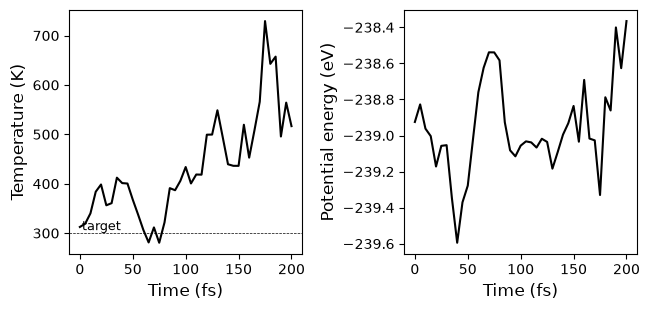

In [4]:
energy = pd.read_csv(MD_DIR / "md_energy.csv")
t_mid = energy["time(fs)"].max() / 2
first_half = energy[energy["time(fs)"] < t_mid]
second_half = energy[energy["time(fs)"] >= t_mid]

print("Columns of md_energy.csv")
print(list(energy.columns))
print("Rows in md_energy.csv")
print(len(energy))
print("Samples counted by the run record")
print(stage["results"]["n_samples"])
print("Temperature at step 0 (K)")
print(round(energy["temperature(K)"].iloc[0], 1))
print("Final temperature (K)")
print(round(energy["temperature(K)"].iloc[-1], 1))
print()
print("Mean temperature over the first half (K)")
print(round(first_half["temperature(K)"].mean(), 1))
print("Mean temperature over the second half (K)")
print(round(second_half["temperature(K)"].mean(), 1))
print("Standard deviation of the temperature over the second half (K)")
print(round(second_half["temperature(K)"].std(), 1))
print("Rows in the second half")
print(len(second_half))

n = len(energy)
blocks = []
for k in range(4):
    block = energy.iloc[k * n // 4:(k + 1) * n // 4]
    blocks.append({"block": k + 1,
                   "rows": len(block),
                   "from (fs)": block["time(fs)"].iloc[0],
                   "to (fs)": block["time(fs)"].iloc[-1],
                   "mean T (K)": round(block["temperature(K)"].mean(), 1),
                   "mean E_pot (eV)": round(block["potential_energy(eV)"].mean(), 3)})
print()
print("Block means")
print(pd.DataFrame(blocks).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(6.6, 3.2))

axes[0].plot(energy["time(fs)"], energy["temperature(K)"], linestyle="-", color="k")
axes[0].axhline(300, color="k", linestyle="--", linewidth=0.5)
axes[0].text(2, 306, "target", fontsize=9)
axes[0].set_xlabel("Time (fs)", fontsize=12)
axes[0].set_ylabel("Temperature (K)", fontsize=12)

axes[1].plot(energy["time(fs)"], energy["potential_energy(eV)"], linestyle="-", color="k")
axes[1].set_xlabel("Time (fs)", fontsize=12)
axes[1].set_ylabel("Potential energy (eV)", fontsize=12)

fig.tight_layout()
plt.show()

## 5. Look at the trajectory

- `read("work/md/md.traj", index=":")` reads every frame of the trajectory file into a list of structures
    - A new run writes frame 0 as well, so the number of frames is the number of steps divided by `--traj-interval`, plus one
    - The frame at position `k` is at step `k * TRAJ_INTERVAL`, and at time `k * TRAJ_INTERVAL * TIMESTEP` in fs
- `np.array(list)` turns a list into an array, so that `==` compares every element at once
- `np.where(array == value)[0]` gives the positions in an array where the condition holds, and here it picks out the O atoms and the Pt atoms by their chemical symbol
- `heights.min(axis=0)` is the lowest value down each column of a table of numbers, which here is the lowest height of each molecule over the frames, and `.round(2)` rounds to two decimals
- The height of an O atom is its z coordinate minus the mean z coordinate of the nine Pt atoms of the top layer in the same frame
    - The top layer is the Pt atoms within 1 Å of the highest Pt atom in frame 0
    - A height is measured to the top layer as it moves, so a slab that breathes does not show up as a height change
- The molecules in the table and the line plot are numbered in the order of their O atoms in the file, which is not the order in which the cell above placed them
    - `sort=True` groups the atoms by element, and within one element the file does not keep the order they had in memory: the first-frame column of the table is the list of the section on the structure in a different order
- In the saved run:
    - Five of the six O atoms end lower than they started, molecules 1, 3, 4, 5 and 6, and one ends higher, molecule 2
    - The largest change is molecule 6, which goes from 4.56 Å to 3.84 Å, a fall of 0.72 Å
    - No O atom is lower than 3.04 Å in any of the 21 frames, and that value is the lowest height of molecule 4, which started at 3.09 Å
- In the figures:
    - The two side views are the first and the last frame, with the time of each as the title
    - The line plot has one line per water molecule against time
    - Read it for whether any molecule comes down to the surface, goes up, or stays where it was placed

Frames in md.traj
21
Time of the last frame (fs)
200.0
Pt atoms in the top layer
9

Height of each O atom above the top Pt layer (Å)
 molecule  first frame  last frame  lowest
        1         4.65        4.63    4.55
        2         3.49        3.67    3.49
        3         4.38        3.71    3.71
        4         3.09        3.04    3.04
        5         5.31        4.67    4.67
        6         4.56        3.84    3.84


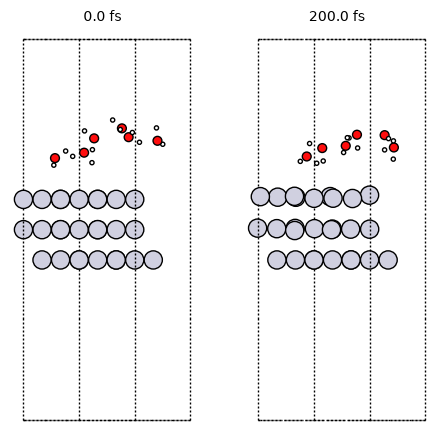

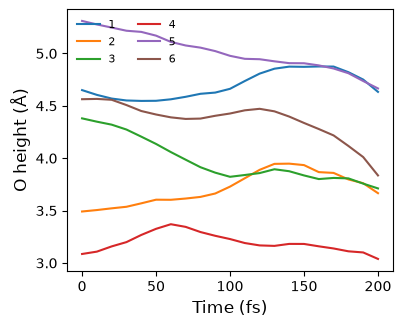

In [5]:
frames = read(MD_DIR / "md.traj", index=":")
frame_time = np.arange(len(frames)) * TRAJ_INTERVAL * TIMESTEP

symbols = np.array(frames[0].get_chemical_symbols())
o_idx = np.where(symbols == "O")[0]
pt_idx = np.where(symbols == "Pt")[0]
z_pt = frames[0].positions[pt_idx, 2]
top_layer = pt_idx[z_pt > z_pt.max() - 1.0]


def o_heights(frame_list):
    # Height of every O atom above the mean z of the top Pt layer, one row per frame.
    return np.array([f.positions[o_idx, 2] - f.positions[top_layer, 2].mean()
                     for f in frame_list])


heights = o_heights(frames)

print("Frames in md.traj")
print(len(frames))
print("Time of the last frame (fs)")
print(float(frame_time[-1]))
print("Pt atoms in the top layer")
print(len(top_layer))
print()
print("Height of each O atom above the top Pt layer (Å)")
print(pd.DataFrame({"molecule": range(1, 7),
                    "first frame": heights[0].round(2),
                    "last frame": heights[-1].round(2),
                    "lowest": heights.min(axis=0).round(2)}).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(5, 4.5))
for ax, k in zip(axes, (0, len(frames) - 1)):
    plot_atoms(frames[k], ax, radii=0.5, rotation="-90x")
    ax.set_title(str(float(frame_time[k])) + " fs", fontsize=10)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(4.2, 3.4))
for m in range(6):
    ax.plot(frame_time, heights[:, m], linestyle="-", label=str(m + 1))
ax.set_xlabel("Time (fs)", fontsize=12)
ax.set_ylabel("O height (Å)", fontsize=12)
ax.legend(fontsize=8, frameon=False, ncol=2)
plt.show()

## 6. Timestep test

- The same structure, the same thermostat and the same temperature, with `--timestep 2.0` and `--steps 100`, written into its own folder `work/md_dt2/`
    - `mlip md run --structure work/md_dt2/POSCAR --mlip mace --ensemble nvt --thermostat langevin --temperature 300 --friction 0.01 --timestep 2.0 --steps 100 --log-interval 10 --traj-interval 20 --device cpu`
    - The structure file is written again into the new folder because the files of a run go next to its structure; it is the same file as before
    - 100 steps of 2.0 fs cover 200 fs, the same simulated time as the 400 steps of 0.5 fs of the main run, with a quarter of the steps
- The command is run four times, in `work/md_dt2/`, `work/md_dt2_b/`, `work/md_dt2_c/` and `work/md_dt2_d/`, because one run is not enough to say what 2.0 fs does
    - The command passes no seed, so the four runs start from different random velocities and feel different random forces
    - The main run of the earlier sections differs from these in the timestep and the number of steps; a comparison of this kind says what these runs did, and it is not a proof of the cause
- `min()` and `max()` of a column give its lowest and its highest value, and `format(x, ".3g")` writes a number with three significant digits, so `3.2e+06` means 3.2 times 10 to the power 6
- The longest O–H distance of a frame is found as follows: for each O atom, the distances to all H atoms are sorted, the two shortest are taken as that molecule's two bonds, and the longest of the twelve bonds is kept
    - It is a definition made for this page, and when a molecule falls apart the two nearest H atoms may no longer be the ones it started with
    - `np.sort(array)` puts the values in increasing order
    - The lowest O height is the lowest value of the O heights of the section on the trajectory, over all frames of a run; a negative value means an O atom is below the top Pt layer
- A general statement, background and not what these runs showed: below a limit set by the fastest vibration, here the O–H stretch, the integration error in the energy stays bounded and oscillates; past that limit it no longer stays bounded, and the energy grows from step to step until the run blows up
    - In a Langevin thermostat the friction removes kinetic energy at a rate proportional to the kinetic energy, and the random force adds energy at a rate set by the target temperature; the two balance at the target, and they cannot hold a run in which the integration error adds more than the friction removes beyond what the random force adds
- In the saved runs:
    - All four commands returned 0 and all four run records say `converged`
    - The highest temperature of the 0.5 fs run is 729 K, and the highest temperatures of the four 2.0 fs runs are 3.2e+06 K, 4.52e+10 K, 3.3e+08 K and 1.01e+14 K
    - The first logged time at which a 2.0 fs run is above 1e+04 K is 160 fs for run 1, 140 fs for run 2, 160 fs for run 3 and 160 fs for run 4
    - The longest O–H distance is 1.06 Å in the 0.5 fs run and between 3.19 Å and 4.71 Å in the four 2.0 fs runs, which is not the distance of a bonded O–H pair
    - The lowest O height is -13.44 Å in run 2 and -2690.49 Å in run 4, which means atoms have been thrown far out of the region of the slab; in runs 1 and 3 it is 2.91 Å and 1.29 Å
    - So in these four runs, four of four left the range of the 0.5 fs run, with the same thermostat, temperature and friction, and each ended with a label of `converged`
- What these runs do not show
    - The page has one 0.5 fs run, so it does not show that 0.5 fs always stays in range; it shows what that run and these four runs did
    - A rerun can give a 2.0 fs run that stays in range for these 200 fs, and four runs are a small sample
    - It does not show where between 0.5 fs and 2.0 fs the limit is, and it did not run 1.0 fs, the default of the command
- In the tables:
    - The first table has one row per run, with the temperature range, the final temperature, the longest O–H distance over the frames, the lowest O height and the status from the run record
    - The second table lists the temperature of each 2.0 fs run at every logged time, so it shows when a run leaves the range of the 0.5 fs run, if it does

In [6]:
DT2_DIRS = [WORK / "md_dt2", WORK / "md_dt2_b", WORK / "md_dt2_c", WORK / "md_dt2_d"]
runs_dt2 = []
return_codes = []

for k, folder in enumerate(DT2_DIRS):
    folder.mkdir(exist_ok=True)
    write(folder / "POSCAR", system, format="vasp", direct=True, sort=True)
    outcome = run_mlip(["md", "run",
                        "--structure", str(folder / "POSCAR"),
                        "--mlip", "mace",
                        "--ensemble", "nvt",
                        "--thermostat", "langevin",
                        "--temperature", "300",
                        "--friction", "0.01",
                        "--timestep", "2.0",
                        "--steps", "100",
                        "--log-interval", "10",
                        "--traj-interval", "20",
                        "--device", "cpu"],
                       show=(k == 0))
    return_codes.append(outcome.returncode)
    runs_dt2.append({"energy": pd.read_csv(folder / "md_energy.csv"),
                     "frames": read(folder / "md.traj", index=":"),
                     "stage": last_stage(folder)})


def longest_oh(frame):
    # Longest of the O-H bonds: for each O the two nearest H atoms.
    sym = np.array(frame.get_chemical_symbols())
    h_idx = np.where(sym == "H")[0].tolist()
    longest = 0.0
    for i in np.where(sym == "O")[0]:
        nearest_two = np.sort(frame.get_distances(int(i), h_idx, mic=True))[:2]
        longest = max(longest, float(nearest_two.max()))
    return longest


compared = [("0.5 fs, 400 steps", energy, frames, stage)]
for k, run in enumerate(runs_dt2):
    compared.append(("2.0 fs, 100 steps, run " + str(k + 1), run["energy"], run["frames"], run["stage"]))

rows = []
for label, table, frame_list, st in compared:
    rows.append({"run": label,
                 "simulated (fs)": table["time(fs)"].max(),
                 "lowest T (K)": format(table["temperature(K)"].min(), ".3g"),
                 "highest T (K)": format(table["temperature(K)"].max(), ".3g"),
                 "final T (K)": format(table["temperature(K)"].iloc[-1], ".3g"),
                 "longest O-H (Å)": round(max(longest_oh(f) for f in frame_list), 2),
                 "lowest O height (Å)": round(float(o_heights(frame_list).min()), 2),
                 "status": st["status"]})

print()
print("Return codes of the four 2.0 fs commands")
print(return_codes)
print()
print("The 0.5 fs run and the four 2.0 fs runs")
print(pd.DataFrame(rows).to_string(index=False))

print()
print("Temperature (K) at each logged time of the four 2.0 fs runs")
by_time = {"time (fs)": runs_dt2[0]["energy"]["time(fs)"]}
for k, run in enumerate(runs_dt2):
    by_time["run " + str(k + 1)] = [format(t, ".3g") for t in run["energy"]["temperature(K)"]]
print(pd.DataFrame(by_time).to_string(index=False))

Command, as you would type it in the terminal
mlip md run --structure work/md_dt2/POSCAR --mlip mace --ensemble nvt --thermostat langevin --temperature 300 --friction 0.01 --timestep 2.0 --steps 100 --log-interval 10 --traj-interval 20 --device cpu



Seconds the command took
14.6



Return codes of the four 2.0 fs commands
[0, 0, 0, 0]

The 0.5 fs run and the four 2.0 fs runs
                     run  simulated (fs) lowest T (K) highest T (K) final T (K)  longest O-H (Å)  lowest O height (Å)    status
       0.5 fs, 400 steps           200.0          281           729         517             1.06                 3.04 converged
2.0 fs, 100 steps, run 1           200.0          353       3.2e+06     3.2e+06             3.19                 2.91 converged
2.0 fs, 100 steps, run 2           200.0          298      4.52e+10    4.52e+10             4.71               -13.44 converged
2.0 fs, 100 steps, run 3           200.0          330       3.3e+08    2.21e+08             3.66                 1.29 converged
2.0 fs, 100 steps, run 4           200.0          246      1.01e+14    1.01e+14             4.11             -2690.49 converged

Temperature (K) at each logged time of the four 2.0 fs runs
 time (fs)    run 1    run 2    run 3    run 4
       0.0      353      298

## 7. Continue a run

- `mlip md run --structure work/md/POSCAR --mlip mace --resume --steps 200 --ensemble nvt --thermostat langevin --temperature 300 --friction 0.01 --timestep 0.5 --log-interval 10 --traj-interval 20 --device cpu`
- What `--resume` does, from the code that runs
    - It reads the last frame of `md.traj` in the folder of `--structure` and uses it as the starting structure, with the velocities that frame holds; the `--structure` file only locates the folder
    - It takes the step count from the last row of `md_energy.csv`, and then runs `--steps` more steps: `--steps` is additional on top of the earlier run, and not a total
    - It appends the new rows to the same `md_energy.csv` and the new frames to the same `md.traj`, adds a block to `md_params.txt`, and adds a stage to the run record
    - It does not draw new random velocities, so the temperature carries on from where the run stopped
- The cell prints the last step in the file before and after, the row and frame counts, the rows around the join, and the stages of the run record
    - A stage's `steps` is the running step count of the whole run at the end of that stage, so after a resume it is the new total and not the 200 that were asked for
- `table[column].between(a, b)` is true for the values from `a` to `b` inclusive, and `table[...]` with it keeps those rows
- `.round(2)` on a table rounds every number in it to two decimals, and `text.count("word")` counts how many times a piece of text occurs in a longer text
- Which flags a resume needs: it does not read the earlier settings back, so every flag you leave out takes the default of `mlip md run`
    - `md_params.txt` is written by the command and not read by it; the settings of the earlier run are not an input of the next
    - So the command above repeats the ensemble, the thermostat, the temperature, the friction, the timestep and the two intervals
    - The next cell shows what happens when they are left out, on a copy of the folder so that the main run is not changed
- In the tables:
    - The join table shows the rows from step 380 to step 420, and the step just after the old end is the first new one; the step of the old end is not written twice
    - If the temperature after the join is near its value before the join and not near the target of 300 K, the velocities were carried over
- In the saved run:
    - The last step goes from 400 to 600, the rows from 41 to 61 and the frames from 21 to 31, which is 200 steps more, 20 rows more and 10 frames more
    - The temperature is 516.63 K at step 400 and 558.28 K at step 410, near its value before the join and not near 300 K
    - The run record has two stages, `md` with 400 steps and `md-resume` with 600

In [7]:
before = pd.read_csv(MD_DIR / "md_energy.csv")
last_step_before = int(before["step"].iloc[-1])
frames_before = len(frames)

result_resume = run_mlip(["md", "run",
                          "--structure", str(MD_DIR / "POSCAR"),
                          "--mlip", "mace",
                          "--resume",
                          "--steps", "200",
                          "--ensemble", "nvt",
                          "--thermostat", "langevin",
                          "--temperature", "300",
                          "--friction", "0.01",
                          "--timestep", str(TIMESTEP),
                          "--log-interval", str(LOG_INTERVAL),
                          "--traj-interval", str(TRAJ_INTERVAL),
                          "--device", "cpu"])

after = pd.read_csv(MD_DIR / "md_energy.csv")
frames_after = len(read(MD_DIR / "md.traj", index=":"))
record = json.loads((MD_DIR / "mliprun_run.json").read_text())

print()
print("First line the command printed")
print(first_lines(result_resume.stdout, 1))
print()
print("Last step in md_energy.csv before the resume")
print(last_step_before)
print("Last step in md_energy.csv after the resume")
print(int(after["step"].iloc[-1]))
print("Rows in md_energy.csv before and after")
print(len(before), len(after))
print("Frames in md.traj before and after")
print(frames_before, frames_after)
print("Resume blocks in md_params.txt")
print((MD_DIR / "md_params.txt").read_text().count("Resume invocation"))
print()
print("Rows around the join")
print(after[after["step"].between(380, 420)].round(2).to_string(index=False))
print()
print("Stages of the run record")
print(pd.DataFrame([{"stage": s["index"], "kind": s["kind"], "status": s["status"],
                     "steps": s["steps"]} for s in record["stages"]]).to_string(index=False))

Command, as you would type it in the terminal
mlip md run --structure work/md/POSCAR --mlip mace --resume --steps 200 --ensemble nvt --thermostat langevin --temperature 300 --friction 0.01 --timestep 0.5 --log-interval 10 --traj-interval 20 --device cpu



Seconds the command took
25.0

First line the command printed
🔁 Resuming from work/md/md.traj (last frame).

Last step in md_energy.csv before the resume
400
Last step in md_energy.csv after the resume
600
Rows in md_energy.csv before and after
41 61
Frames in md.traj before and after
21 31
Resume blocks in md_params.txt
1

Rows around the join
 step  time(fs)  temperature(K)  total_energy(eV)  potential_energy(eV)  kinetic_energy(eV)
  380     190.0          495.67           -236.09               -238.40                2.31
  390     195.0          564.27           -236.00               -238.63                2.63
  400     200.0          516.63           -235.96               -238.37                2.40
  410     205.0          558.28           -236.11               -238.71                2.60
  420     210.0          454.14           -236.22               -238.33                2.11

Stages of the run record
 stage      kind    status  steps
     0        md converged    400
     1

### 7a. What a resume does with a flag you leave out

- The copy of `work/md/` in `work/md_resume_check/` is resumed for 20 steps with `--structure`, `--resume`, `--steps 20`, the model and the device, and no other flag
    - `mlip md run --structure work/md_resume_check/POSCAR --mlip mace --resume --steps 20 --device cpu`
- The command echoes the settings it is about to use, and the cell prints the lines of the ensemble, the thermostat, the temperature, the friction, the timestep and the number of steps
    - The echoed timestep is the one that matters most: the time column of the new rows is the step times the timestep of this invocation, so a resume with a timestep other than the first run's makes the time column inconsistent
- `shutil.copytree(a, b, dirs_exist_ok=True)` copies the folder `a` into `b`, and `table.tail(4)` keeps the last four rows
    - `table[["a", "b"]]` with double brackets keeps only the columns named in the inner list, here `step` and `time(fs)`
- `md_energy.csv` of the copy is read to show the step and the time of its last rows
- In the table:
    - The rows up to step 600 carry the time of the main run's 0.5 fs, and the rows after it carry the time of the timestep that was echoed
    - In the saved run step 600 is at 300.0 fs and step 610 is at 610.0 fs, so the time column jumps by 310 fs for 10 steps
    - The run itself used the echoed 1.0 fs for those 20 steps, and that is the larger problem, because a different timestep changes the dynamics; the time column only makes it visible

In [8]:
CHECK_DIR = WORK / "md_resume_check"
shutil.copytree(MD_DIR, CHECK_DIR, dirs_exist_ok=True)

result_check = run_mlip(["md", "run",
                         "--structure", str(CHECK_DIR / "POSCAR"),
                         "--mlip", "mace",
                         "--resume",
                         "--steps", "20",
                         "--device", "cpu"])

print()
print("Settings the command echoed")
echoed = [line.strip() for line in result_check.stdout.splitlines()
          if line.strip().startswith(("Ensemble:", "Thermostat:", "Temperature:", "Friction:",
                                      "Steps:", "Timestep:"))]
print("\n".join(echoed))

check = pd.read_csv(CHECK_DIR / "md_energy.csv")
print()
print("Last rows of md_energy.csv in the copy")
print(check[["step", "time(fs)"]].tail(4).to_string(index=False))

Command, as you would type it in the terminal
mlip md run --structure work/md_resume_check/POSCAR --mlip mace --resume --steps 20 --device cpu



Seconds the command took
6.9

Settings the command echoed
Ensemble:    NVT
Thermostat:  langevin
Friction:    0.01 fs⁻¹
Temperature: 300.0 K
Steps:       20
Timestep:    1.0 fs

Last rows of md_energy.csv in the copy
 step  time(fs)
  590     295.0
  600     300.0
  610     610.0
  620     620.0


## 8. What C5 asks you to decide

- Canon `C5` names four decisions that are set per project and never taken from a default: the ensemble, the temperature, the timestep and the total number of steps
    - The total number of steps is the total length, and how much of it is equilibration and how much is production is part of that decision
    - The project's record, below, also fixes the thermostat and its friction
- The project's own record is the example of what a decision looks like; this repository keeps it in `projects/ew2gc/DECISIONS.md`, and the entry below is the one in the project's `CANON.md` as it read on 2026-10-12
    - "Phase 5 slab+water production MDs run NVT Langevin, 300 K, friction 0.01 fs⁻¹, 0.5 fs timestep, 175 ps total = 50 ps equilibration discarded + 125 ps production, with a mandatory block-trend check and `--resume` extension before any γ enters a table"
    - γ is a quantity of that project, defined in its energetics items and not computed in this module
    - The entry names a block-trend check and does not define it here; the block means of the section on reading the run are one plain way of looking at a trend in blocks, and the project's own definition is the one to use
- The table lays three columns of values side by side
    - This notebook's values, which are the ones in the commands above
    - The values `mlip md run` takes if you leave the flag out: the ensemble, the thermostat, the temperature, the friction and the timestep are the ones it echoed in the section above for a resume with those flags left out, and the steps default is the 1000 of its option list, which the help text of `mlip md run` shows
    - The project's recorded values
- The comparison, counted by the cell
    - The thermostat, the temperature, the friction and the timestep of this notebook are the project's
    - The length is not: 400 steps of 0.5 fs is 0.2 ps, and the project's 175 ps is 350000 steps of 0.5 fs, which is the ratio the cell prints
    - The default timestep is not the project's; the group's master canon records that 1.0 fs is too coarse for systems that contain hydrogen, and this page tested 2.0 fs and not 1.0 fs
- The last number is the time of a project-length run at this notebook's speed, for this 45-atom system on this computer with the CPU
    - It is a scale for the word steps and not a forecast for the project, whose system and computer are different

In [9]:
steps_run = 400
timestep_fs = 0.5
simulated_ps = steps_run * timestep_fs / 1000
project_ps = 175
project_steps = int(project_ps * 1000 / timestep_fs)
seconds_per_step = stage["walltime_s"] / stage["steps"]

rows = [{"setting": "ensemble", "this notebook": "nvt", "default if left out": "nvt", "project": "NVT"},
        {"setting": "thermostat", "this notebook": "langevin", "default if left out": "langevin",
         "project": "Langevin"},
        {"setting": "temperature (K)", "this notebook": 300, "default if left out": 300, "project": 300},
        {"setting": "friction (1/fs)", "this notebook": 0.01, "default if left out": 0.01, "project": 0.01},
        {"setting": "timestep (fs)", "this notebook": 0.5, "default if left out": 1.0, "project": 0.5},
        {"setting": "steps", "this notebook": steps_run, "default if left out": 1000,
         "project": project_steps},
        {"setting": "length (ps)", "this notebook": simulated_ps, "default if left out": 1.0,
         "project": project_ps}]

print("Settings of an MD run")
print(pd.DataFrame(rows).to_string(index=False))
print()
print("Length of the project run divided by the length of this run")
print(round(project_ps / simulated_ps))
print("Seconds per step of the main run, from the run record")
print(round(seconds_per_step, 3))
print("Hours for the project's number of steps at that speed")
print(round(project_steps * seconds_per_step / 3600, 1))

Settings of an MD run
        setting this notebook default if left out  project
       ensemble           nvt                 nvt      NVT
     thermostat      langevin            langevin Langevin
temperature (K)           300                 300      300
friction (1/fs)          0.01                0.01     0.01
  timestep (fs)           0.5                 1.0      0.5
          steps           400                1000   350000
    length (ps)           0.2                 1.0      175

Length of the project run divided by the length of this run
875
Seconds per step of the main run, from the run record
0.099
Hours for the project's number of steps at that speed
9.6


## Check yourself

1. A colleague sends you the `md_energy.csv` of a run whose last row has a temperature of 301 K for a target of 300 K, and says the run is equilibrated.
   What do you look at before you agree?
2. After the section on continuing a run, `work/md/` ends at step 600, and you type `mlip md run --structure work/md/POSCAR --mlip mace --resume` and nothing else in the folder of the notebook.
   Where does the run end, and what else about it is not what the earlier steps of that folder used?
3. A run at `--timestep 2.0` ends with a return code of 0 and a `status` of `converged` in its run record.
   Can you use it, and what do you do instead?

<details>
<summary>Answers</summary>

- One row says nothing: the temperature fluctuates around the target, so a value near it is expected at any stage. Look at the whole temperature trace and at block means of the temperature and the potential energy, which should not trend over the part you call production, and read the discarded part and its length from the project's `CANON.md`, canon `C5`
- It ends at step 1600: `--steps` was left out, so it takes its default of 1000, and on a resume `--steps` is additional on top of the step count of the old `md_energy.csv`, so 600 plus 1000 is 1600; it carries on from the last frame of `md.traj`. Everything else is not carried: the command does not read the earlier settings back, so the ensemble, the thermostat, the temperature, the friction and the log interval all take the defaults of `mlip md run`, and so do `--device`, which falls back to `auto` when it is left out, `--traj-interval`, which falls back to 100 against the 20 used on the page, and `--timestep`, which falls back to 1.0 fs against the 0.5 fs of every step already in the folder, which also makes the time column inconsistent. Every flag is repeated on a resume
- No. The return code and the `converged` status only say that the requested steps ran. The temperature trace and the O–H distances are what show whether the run is usable, and in the four 2.0 fs runs of this notebook they show that it is not. The timestep is a decision of canon `C5` and it is set by what the fastest motion allows; the project records 0.5 fs, so you run again with the recorded timestep and read the temperature trace before you trust any number from it

</details>